In [3]:
from PIL import Image
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent
path = ROOT / "data" / "preprocessed_data" / "corrected.tif"

(684, 428) (684, 428)


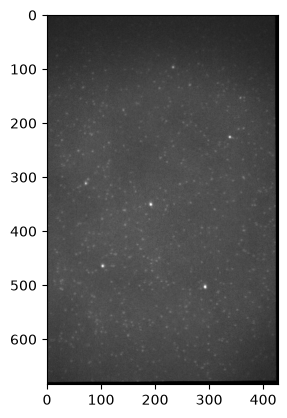

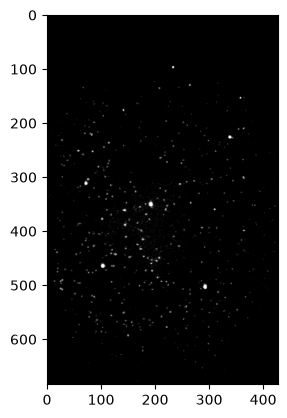

In [4]:
with Image.open(path) as image:
    image.seek(0)
    frame = np.array(image)

left = frame[:, :428]    # columns 0–427
right = frame[:, 428:]  # columns 428–855
print(left.shape, right.shape)  # both (684, 428)
right_centred = np.clip(right.astype(np.float32) - right.mean(), 0, right.max())

plt.imshow(right, cmap="gray", vmin=300, vmax=1500)
plt.show()
plt.imshow(right_centred, cmap="gray", vmin=100, vmax=300)
plt.show()

In [5]:
from picasso.localize import localize_frames

In [8]:
# Detection settings: starting values to explore, not calibrated thresholds.
params = {
    "Box Size": 7,
    "Min. Net Gradient": 1000,
}

# Placeholder camera conversion values for exploring spot positions.
# Replace these with your camera's calibration before interpreting photon counts.
camera_info = {
    "Baseline": 0,
    "Sensitivity": 1.0,
    "Gain": 1,
    "Pixelsize": 117,  # nm; your TIFF metadata says approximately 0.117 µm
}

right_locs = localize_frames(
    right_centred[np.newaxis, :, :],
    info=None,
    params=params,
    camera_info=camera_info,
    fitting_method="gausslq",
    threaded=False,
)

print(f"Right: {len(right_locs)} localisations")

right_locs.head()

Right: 565 localisations


,frame,x,y,photons,sx,sy,bg,lpx,lpy,ellipticity,net_gradient,iterations,chi_square
0,0,280.631134,90.017815,607.603943,1.232871,0.915455,-1.774419,0.066751,0.050602,0.257461,1146.233154,3,1158.439941
385,0,26.208105,491.884705,9398.701172,2.299170,3.783247,24.339874,0.036641,0.059997,0.392276,1840.591309,7,44580.492188
384,0,285.637207,491.876587,1015.938599,1.153813,1.014031,53.158646,0.069077,0.061233,0.121148,1825.834229,3,18605.052734
383,0,50.678219,491.925598,2135.051758,1.445710,1.807967,49.312958,0.058350,0.072464,0.200367,2416.504150,3,11733.178711
382,0,13.930126,492.258392,1234.444092,1.260230,1.096779,70.716080,0.072566,0.063656,0.129699,2609.107910,4,14274.087891


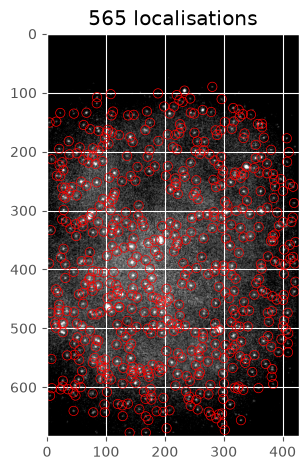

In [9]:
vmin, vmax = np.percentile(right_centred, [1, 99.8])
plt.imshow(right_centred, cmap="gray", vmin=vmin, vmax=vmax)

plt.scatter(
    right_locs["x"], right_locs["y"],
    s=45, facecolors="none", edgecolors="red",
)
plt.title(f"{len(right_locs)} localisations")

plt.tight_layout()
plt.show()